# load model

In [1]:
import pandas as pd
import numpy as np
import time
from tqdm import tqdm
from collections import defaultdict
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import random
from scipy.special import expit # Sigmoid function

In [2]:
ratings_full = pd.read_csv('../data/processed_full/user_item_processed_data.csv')
user_df = pd.read_csv('../data/processed_full/user_features.csv')
item_df = pd.read_csv('../data/processed_full/item_features.csv')

print("Data simulation complete.")
print("\nRatings Full DF shape:", ratings_full.shape)
print("\nItem Features DF shape:", item_df.shape)
print("\nUser Features DF shape:", user_df.shape)
ratings_full.head(5)

Data simulation complete.

Ratings Full DF shape: (1400102, 109)

Item Features DF shape: (27197, 115)

User Features DF shape: (46660, 115)


,user_id,item_id,rating,sleep quality,value,rooms,service,cleanliness,location,text_emb_0,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,1521,19,1.0,NaN,1.0,NaN,1.0,1.0,NaN,-0.041622,...,0.051783,0.090821,0.023550,-0.028458,0.022709,-0.017830,0.030984,-0.066530,-0.004420,0.022615
1,1524,19,1.0,NaN,NaN,1.0,1.0,NaN,0.6,0.094268,...,0.007869,-0.021458,-0.011069,0.033729,-0.014652,0.031356,0.019260,-0.038565,-0.017441,0.011813
2,1527,19,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.226007,...,0.035656,0.022072,0.031577,-0.085225,-0.019208,0.009750,-0.041887,0.036383,0.069358,0.071002
3,1529,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.026531,...,0.003374,0.041171,0.008375,0.020658,0.000111,-0.012515,-0.019410,-0.014252,0.023997,0.030726
4,1530,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.133377,...,-0.012842,-0.004858,0.077540,-0.057574,0.024631,-0.011781,-0.032293,-0.060140,0.048414,0.012466


In [3]:
# load the model
with open('lightfm_hybrid_model_75e_256d.pkl', 'rb') as f:
    loaded_checkpoint = pickle.load(f)
    
model = loaded_checkpoint['model']
user_id_map = loaded_checkpoint['user_id_map']
item_id_map = loaded_checkpoint['item_id_map']
inv_user_id_map = loaded_checkpoint['inv_user_id_map']
inv_item_id_map = loaded_checkpoint['inv_item_id_map']
user_features = loaded_checkpoint['user_features']
item_features = loaded_checkpoint['item_features']
train_interactions = loaded_checkpoint['train_interactions']
test_interactions = loaded_checkpoint['test_interactions']

/Users/maksiuuuuuuu/miniconda3/envs/recsys_env/lib/python3.11/site-packages/lightfm/_lightfm_fast.py:9: UserWarning: LightFM was compiled without OpenMP support. Only a single thread will be used.
  warnings.warn(


In [4]:
k_values = [10, 20, 50, 100]
train_interactions_csr = train_interactions.tocsr()
test_interactions_csr = test_interactions.tocsr()

# Pre-calculate true items for test users (as you did)
true_items_per_user = {
    u: dict(zip(test_interactions_csr[u].indices, test_interactions_csr[u].data))
    for u in range(test_interactions_csr.shape[0]) if test_interactions_csr[u].nnz > 0
}

test_user_indices = list(true_items_per_user.keys())
all_item_indices = np.arange(len(item_id_map))

# # --- Accumulators for Metrics ---
# ndcg_scores = {k: [] for k in k_values}
# hit_counts = {k: 0 for k in k_values}
# unique_items_recommended = {k: set() for k in k_values}
# recommendation_counts = {k: defaultdict(int) for k in k_values} # For Diversity
# total_users_evaluated = 0

In [5]:
# --- CONFIGURATION ---
EVAL_POOL_SIZE = 5000   # Large enough to minimize group overlap
N_GROUPS_PER_SIZE = 1000 # Large enough for smooth Confidence Intervals
GROUP_SIZES = [4, 6, 8, 10, 12, 15]
TOP_K = 100
strategies = ['additive', 'least_misery', 'most_pleasure']
rng = np.random.default_rng(42)

In [6]:
# 1. Select the pool of users
# We filter for users who actually exist in the test set mapping
valid_test_users = list(true_items_per_user.keys())

if len(valid_test_users) > EVAL_POOL_SIZE:
    # Randomly sample without replacement
    eval_user_ids = np.random.choice(valid_test_users, size=EVAL_POOL_SIZE, replace=False)
else:
    eval_user_ids = np.array(valid_test_users)

print(f"Preparing evaluation pool with {len(eval_user_ids)} users...")

Preparing evaluation pool with 5000 users...


## Here we are precalculating rankings for all user! - decoupled approach!

In [7]:
# 2. Pre-calculate Scores (Batch Prediction)
# This prevents predicting millions of times inside the loop
n_items = len(item_id_map)
user_indices_repeat = np.repeat(eval_user_ids, n_items)
item_indices_tile = np.tile(np.arange(n_items), len(eval_user_ids))

print("Running batch prediction (this might take 30-60 seconds)...")
flat_scores = model.predict(
    user_indices_repeat, 
    item_indices_tile, 
    user_features=user_features, 
    item_features=item_features,
    num_threads=12
)

# Reshape to (n_pool_users, n_items)
precalc_scores = flat_scores.reshape(len(eval_user_ids), n_items)

Running batch prediction (this might take 30-60 seconds)...


In [8]:
# 3. Pre-calculate Training Masks
# We need to know which items each user has already seen to exclude them.
print("Building training masks...")
train_mask = np.zeros(precalc_scores.shape, dtype=bool)

# We need to map Real User ID -> Index in our precalc matrix (0 to 4999)
pool_id_to_index = {uid: i for i, uid in enumerate(eval_user_ids)}

for real_uid in eval_user_ids:
    matrix_idx = pool_id_to_index[real_uid]
    # Get items seen in training
    seen_items = train_interactions_csr[real_uid].indices
    train_mask[matrix_idx, seen_items] = True

print("Pre-calculation complete. Ready for Simulation.")

Building training masks...
Pre-calculation complete. Ready for Simulation.


In [9]:
def aggregate_scores(group_scores, strategy):
    """
    group_scores: (group_size, n_items) array
    """
    if strategy == 'additive': # Average
        return np.mean(group_scores, axis=0)
    
    elif strategy == 'least_misery': # Min
        return np.min(group_scores, axis=0)
    
    elif strategy == 'most_pleasure': # Max
        return np.max(group_scores, axis=0)
    

# Run & Evaluate Random and Similarity-Based groups

In [10]:
def calculate_group_ndcg(group_real_ids, top_k_items, k, true_items_map):
    """Calculates average nDCG for the group members."""
    member_ndcgs = []
    
    for uid in group_real_ids:
        true_items = true_items_map.get(uid, {})
        if not true_items: continue
            
        dcg = 0.0
        idcg = 0.0
        
        # DCG
        for rank, item_idx in enumerate(top_k_items):
            if item_idx in true_items:
                # Assuming binary relevance (1 or 0) for simplicity in implicit feedback
                dcg += 1.0 / np.log2(rank + 2)
        
        # IDCG
        n_poss = min(len(true_items), k)
        for rank in range(n_poss):
            idcg += 1.0 / np.log2(rank + 2)
            
        member_ndcgs.append(dcg / idcg if idcg > 0 else 0)
        
    return np.mean(member_ndcgs) if member_ndcgs else 0

In [11]:
from sklearn.cluster import KMeans
from collections import defaultdict

def get_similarity_groups(model, user_features, pool_ids, size, n_groups):
    """Generates groups based on latent feature clusters."""
    # Get embeddings only for the pool
    _, all_embeddings = model.get_user_representations(features=user_features)
    pool_embeddings = all_embeddings[pool_ids]
    
    # Cluster
    # We want clusters roughly the size of the target group size
    # But for robustness, let's create slightly larger clusters and sample from them
    n_clusters = max(1, len(pool_ids) // (size * 2)) 
    kmeans = KMeans(n_clusters=n_clusters, n_init=5, random_state=42)
    labels = kmeans.fit_predict(pool_embeddings)
    
    cluster_map = defaultdict(list)
    for idx, label in enumerate(labels):
        cluster_map[label].append(pool_ids[idx])
        
    groups = []
    cluster_keys = list(cluster_map.keys())
    
    count = 0
    while count < n_groups:
        # Pick a random cluster
        c_key = random.choice(cluster_keys)
        members = cluster_map[c_key]
        
        if len(members) >= size:
            # Sample users from this similar cluster
            groups.append(random.sample(members, size))
            count += 1
            
    return groups

def get_random_groups(pool_ids, size, n_groups):
    groups = []
    pool = list(pool_ids)
    for _ in range(n_groups):
        groups.append(random.sample(pool, size))
    return groups

In [12]:
# --- MAIN SIMULATION LOOP ---
results_data = []

print("Starting Simulation...")

for g_size in GROUP_SIZES:
    print(f"\nProcessing Group Size: {g_size}")
    
    # 1. Generate Groups
    # A. Random
    rand_groups = get_random_groups(eval_user_ids, g_size, N_GROUPS_PER_SIZE)
    # B. Similar
    sim_groups = get_similarity_groups(model, user_features, eval_user_ids, g_size, N_GROUPS_PER_SIZE)
    
    # Combine tasks: (GroupType, ListOfGroups)
    tasks = [('Random', rand_groups), ('Similarity', sim_groups)]
    
    for group_type, groups_list in tasks:
        print(f"  > Evaluating {group_type} grouping ({len(groups_list)} groups)...")
        
        for group in tqdm(groups_list, leave=False):
            # 1. Retrieve Pre-calculated scores
            # Map Real UIDs -> Matrix Indices
            matrix_indices = [pool_id_to_index[uid] for uid in group]
            
            # Extract (Group_Size, N_Items)
            g_scores_raw = precalc_scores[matrix_indices]
            
            # 2. Apply Masking (Set seen items to -inf)
            g_mask = train_mask[matrix_indices]
            # We copy to avoid modifying the global precalc array
            g_scores = g_scores_raw.copy()
            g_scores[g_mask] = -np.inf
            
            # 3. Apply Strategies
            for strategy in strategies:
                agg_scores = aggregate_scores(g_scores, strategy)
                
                # 4. Rank
                # argpartition is O(n), faster than argsort O(n log n)
                top_k_unsorted = np.argpartition(-agg_scores, TOP_K)[:TOP_K]
                # Sort just top K for exact nDCG
                top_k_sorted = top_k_unsorted[np.argsort(-agg_scores[top_k_unsorted])]
                
                # 5. Calculate nDCG
                score = calculate_group_ndcg(group, top_k_sorted, TOP_K, true_items_per_user)
                
                results_data.append({
                    'Group_Size': g_size,
                    'Grouping_Method': group_type,
                    'Strategy': strategy,
                    'nDCG': score
                })

df_results = pd.DataFrame(results_data)
print("\nSimulation Complete.")

Starting Simulation...

Processing Group Size: 4
  > Evaluating Random grouping (1000 groups)...


  > Evaluating Similarity grouping (1000 groups)...



Processing Group Size: 6
  > Evaluating Random grouping (1000 groups)...


  > Evaluating Similarity grouping (1000 groups)...



Processing Group Size: 8
  > Evaluating Random grouping (1000 groups)...


  > Evaluating Similarity grouping (1000 groups)...


... (3 outputs left out)

  > Evaluating Similarity grouping (1000 groups)...



Processing Group Size: 15
  > Evaluating Random grouping (1000 groups)...


  > Evaluating Similarity grouping (1000 groups)...



Simulation Complete.


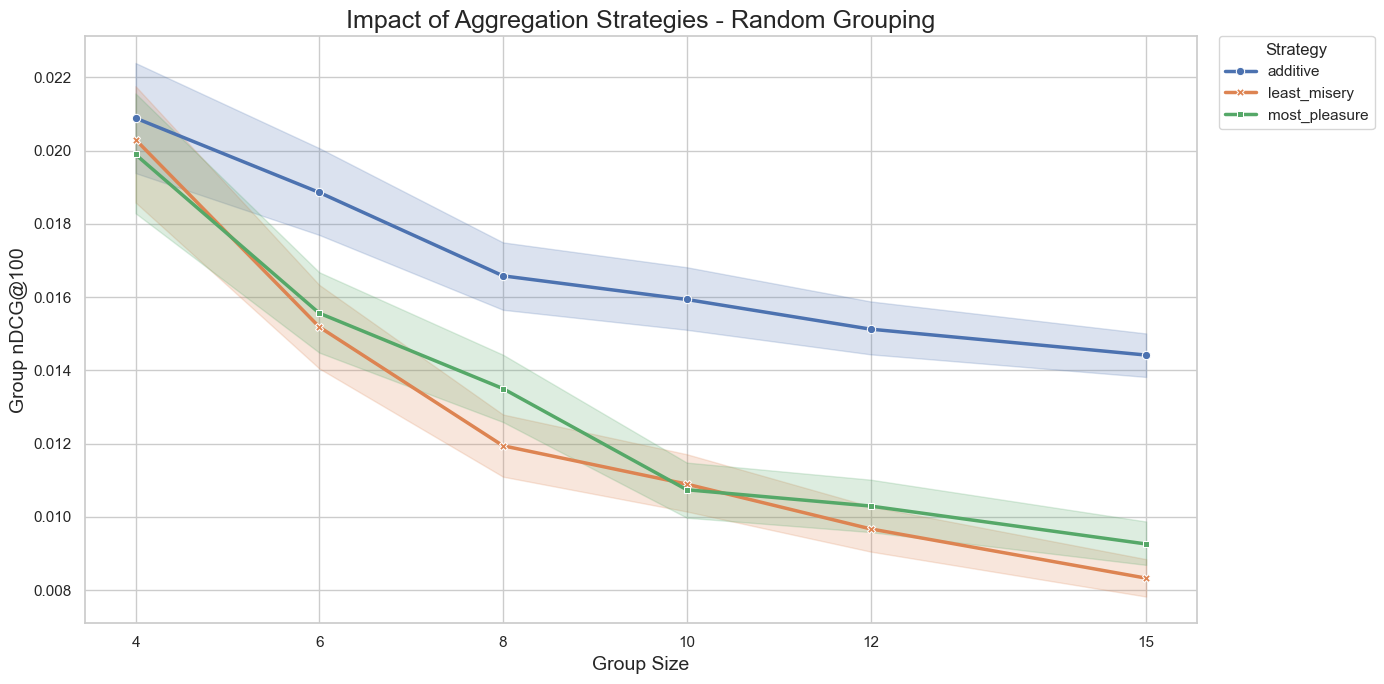

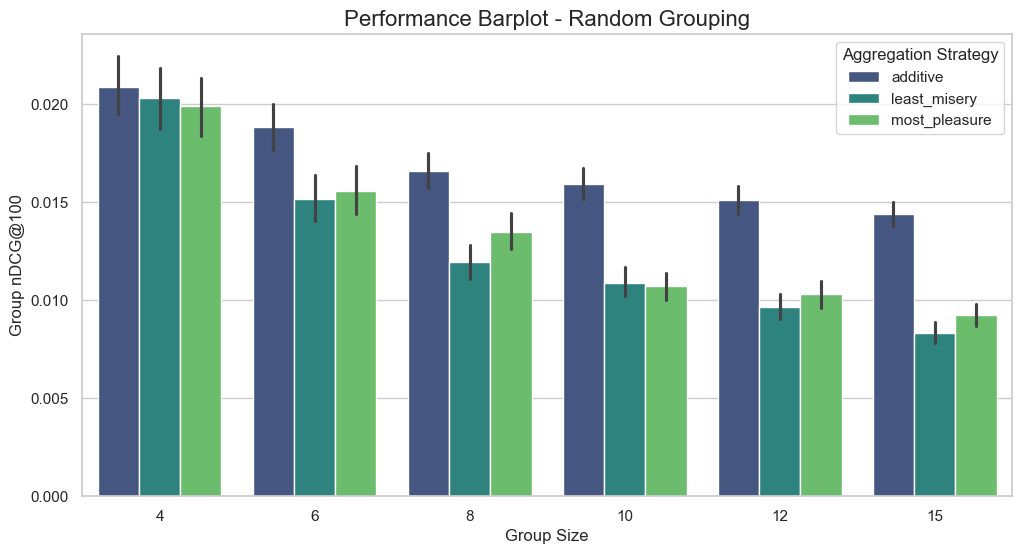


Detailed Statistics for Random Grouping:


mean       std
Group_Size Strategy                         
4          additive       0.020886  0.024218
           least_misery   0.020299  0.025206
           most_pleasure  0.019893  0.025124
6          additive       0.018855  0.018875
           least_misery   0.015184  0.018420
           most_pleasure  0.015560  0.018634
8          additive       0.016579  0.015414
           least_misery   0.011941  0.013664
           most_pleasure  0.013501  0.015352
10         additive       0.015935  0.013260
           least_misery   0.010894  0.012085
           most_pleasure  0.010741  0.011555
12         additive       0.015124  0.011538
           least_misery   0.009673  0.010185
           most_pleasure  0.010295  0.011164
15         additive       0.014417  0.010118
           least_misery   0.008327  0.008353
           most_pleasure  0.009260  0.009318

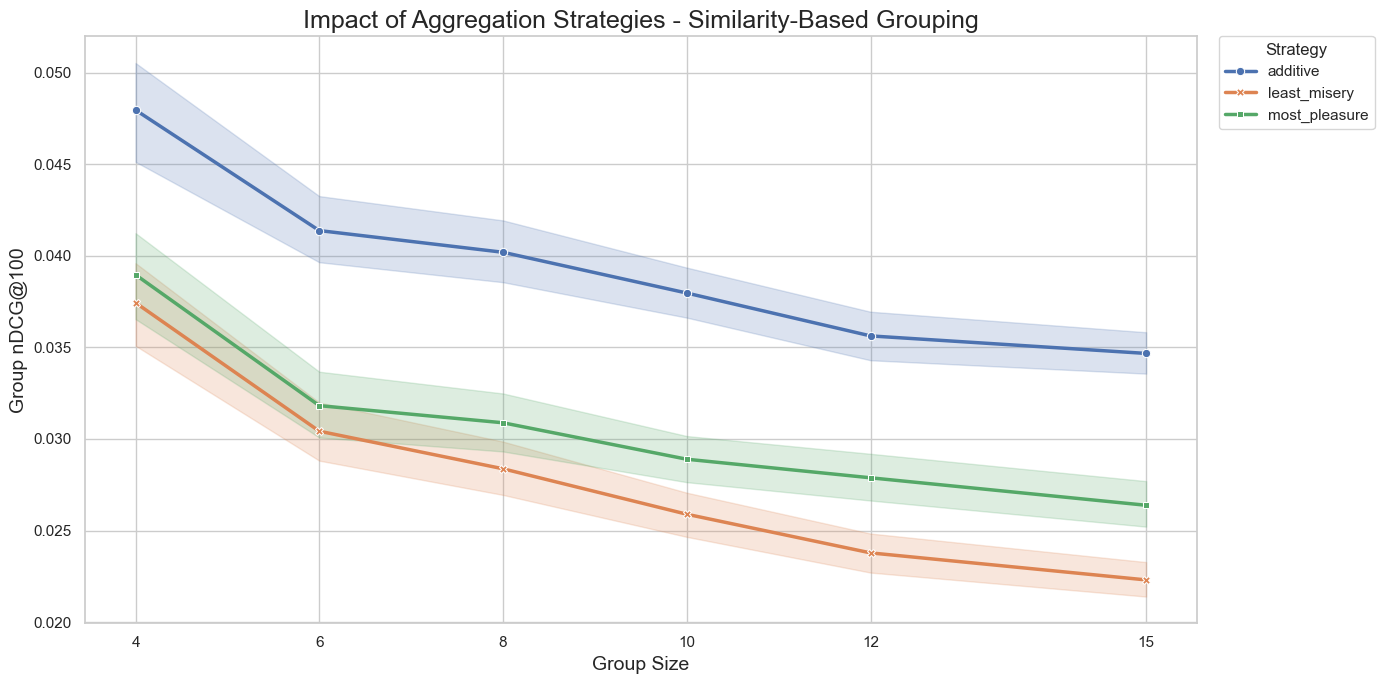

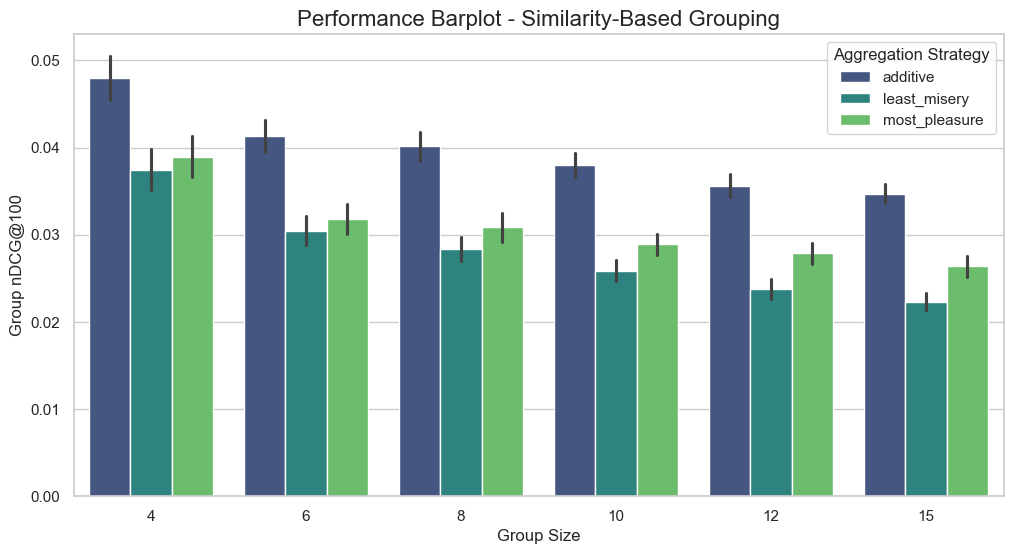


Detailed Statistics for Similarity-Based Grouping:


mean       std
Group_Size Strategy                         
4          additive       0.047961  0.042787
           least_misery   0.037439  0.037424
           most_pleasure  0.038967  0.037971
6          additive       0.041378  0.029312
           least_misery   0.030424  0.025872
           most_pleasure  0.031819  0.027800
8          additive       0.040193  0.027545
           least_misery   0.028372  0.023315
           most_pleasure  0.030883  0.026730
10         additive       0.037968  0.023283
           least_misery   0.025890  0.019465
           most_pleasure  0.028893  0.021039
12         additive       0.035627  0.021651
           least_misery   0.023779  0.017721
           most_pleasure  0.027879  0.020531
15         additive       0.034670  0.018007
           least_misery   0.022303  0.015732
           most_pleasure  0.026379  0.019288

In [13]:
# --- VISUALIZATION SETUP ---

def plot_results(df, title_suffix):
    """Helper to generate your specific plots"""
    
    # 1. Line Plot
    sns.set_theme(style="whitegrid", context="notebook")
    plt.figure(figsize=(14, 7))
    
    ax = sns.lineplot(
        data=df, 
        x="Group_Size", 
        y="nDCG", 
        hue="Strategy",
        style="Strategy",
        markers=True,
        dashes=False,
        linewidth=2.5,
        errorbar=('ci', 95)
    )

    plt.title(f"Impact of Aggregation Strategies - {title_suffix}", fontsize=18)
    plt.ylabel(f"Group nDCG@{TOP_K}", fontsize=14)
    plt.xlabel("Group Size", fontsize=14)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title="Strategy")
    plt.xticks(GROUP_SIZES)
    plt.tight_layout()
    plt.show()

    # 2. Bar Plot
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=df, 
        x="Group_Size", 
        y="nDCG", 
        hue="Strategy", 
        palette="viridis",
        errorbar=('ci', 95) 
    )

    plt.title(f"Performance Barplot - {title_suffix}", fontsize=16)
    plt.ylabel(f"Group nDCG@{TOP_K}", fontsize=12)
    plt.xlabel("Group Size", fontsize=12)
    plt.legend(title="Aggregation Strategy", loc='upper right')
    plt.show()
    
    # 3. Stats
    print(f"\nDetailed Statistics for {title_suffix}:")
    summary = df.groupby(['Group_Size', 'Strategy'])['nDCG'].describe()[['mean', 'std']]
    display(summary)

# --- EXECUTE PLOTTING ---

# 1. Random Grouping Results
df_random = df_results[df_results['Grouping_Method'] == 'Random']
plot_results(df_random, "Random Grouping")

# 2. Similarity Grouping Results
df_sim = df_results[df_results['Grouping_Method'] == 'Similarity']
plot_results(df_sim, "Similarity-Based Grouping")

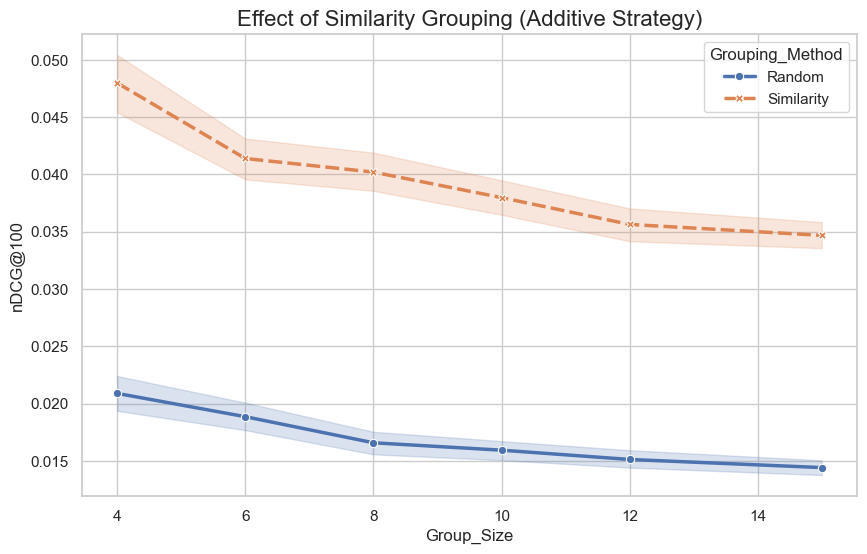

In [14]:
plt.figure(figsize=(10, 6))
# Filter for just the 'additive' (Average) strategy to keep plot clean
subset = df_results[df_results['Strategy'] == 'additive']

sns.lineplot(
    data=subset,
    x="Group_Size",
    y="nDCG",
    hue="Grouping_Method",
    style="Grouping_Method",
    markers=True,
    linewidth=2.5,
    errorbar=('ci', 95)
)
plt.title("Effect of Similarity Grouping (Additive Strategy)", fontsize=16)
plt.ylabel("nDCG@100", fontsize=12)
plt.show()

# select a single highly similar group of 6 users with ID and evaluation

Selected Similarity Group (IDs): [33073, 2324, 19125, 23358, 41239, 16697]

--- Strategy Evaluation ---
Strategy: additive        | nDCG@100: 0.0705
Strategy: least_misery    | nDCG@100: 0.0701
Strategy: most_pleasure   | nDCG@100: 0.0548

--- Group Profile Analysis (What they liked in Training) ---
User 33073: Liked ['0.7745454545454545', '0.7780821917808219', '0.9145833333333334'] ...
User 2324: Liked ['0.8', '0.7768115942028986', '0.8194444444444444'] ...
User 19125: Liked ['0.75', '0.7884057971014493', '0.8800000000000001'] ...
User 23358: Liked ['0.8333333333333334', '0.908433734939759', '0.8029126213592234'] ...
User 41239: Liked ['0.8166666666666667', '0.7317073170731707', '0.782608695652174'] ...
User 16697: Liked ['0.8699999999999999', '0.782608695652174', '0.775'] ...

--- Recommended Items by Strategy (Top 5) ---
[ADDITIVE]: 0.8144486692015208, 0.9424, 0.861111111111111, 0.8400000000000001, 0.8664705882352941
[LEAST_MISERY]: 0.8144486692015208, 0.9165354330708662, 0.86647058

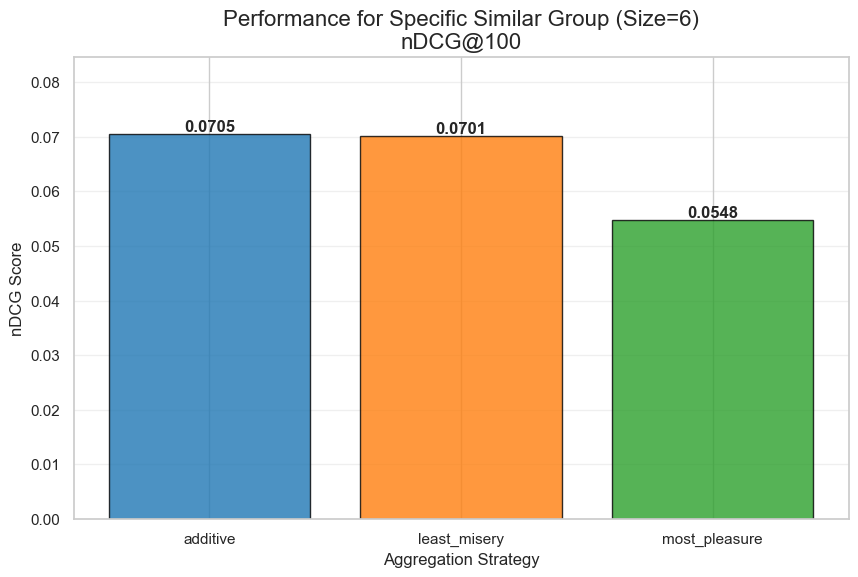

In [18]:
# --- 1. Select a Single Highly Similar Group of 6 ---

# Re-generate clusters specifically to extract one strict group
# We use the embeddings for the pool of users we created earlier
_, all_embeddings = model.get_user_representations(features=user_features)
pool_embeddings = all_embeddings[eval_user_ids]

# Use a high number of clusters to force tight similarity
kmeans_specific = KMeans(n_clusters=len(eval_user_ids)//10, n_init=10, random_state=99)
labels_specific = kmeans_specific.fit_predict(pool_embeddings)

# Find a cluster that has at least 6 members
cluster_counts = defaultdict(list)
for idx, label in enumerate(labels_specific):
    cluster_counts[label].append(eval_user_ids[idx])

# Pick the first cluster that has >= 6 members
target_group_ids = []
for label, members in cluster_counts.items():
    if len(members) >= 6:
        target_group_ids = members[0:6] # Take top 6
        break

print(f"Selected Similarity Group (IDs): {target_group_ids}")

# --- 2. Retrieve Data for Analysis ---

# Helper to get item details (assuming item_df has 'item_id' and some descriptive col)
# We will try to find a 'title' or 'name' column, otherwise use ID
item_desc_col = 'title' if 'title' in item_df.columns else item_df.columns[1] 

def get_item_names(item_indices):
    # Convert internal LightFM indices to original IDs
    original_ids = [inv_item_id_map[i] for i in item_indices]
    # Lookup in dataframe
    names = []
    for oid in original_ids:
        # subset df
        match = item_df[item_df['item_id'] == oid]
        if not match.empty:
            names.append(str(match.iloc[0][item_desc_col]))
        else:
            names.append(str(oid))
    return names

# --- 3. Process Evaluation for this Group ---

# Get Indices
group_matrix_indices = [pool_id_to_index[uid] for uid in target_group_ids]

# Get Scores & Mask
raw_scores = precalc_scores[group_matrix_indices].copy()
group_mask = train_mask[group_matrix_indices]
raw_scores[group_mask] = -np.inf # Mask seen items

group_results = {}
top_items_per_strategy = {}

print("\n--- Strategy Evaluation ---")

for strat in strategies:
    # Aggregate
    agg = aggregate_scores(raw_scores, strat)
    
    # Rank Top 100 for Metric
    top_k_indices = np.argpartition(-agg, 100)[:100]
    top_k_sorted = top_k_indices[np.argsort(-agg[top_k_indices])]
    
    # Calculate Metric
    ndcg_val = calculate_group_ndcg(target_group_ids, top_k_sorted, 100, true_items_per_user)
    group_results[strat] = ndcg_val
    
    # Store Top 5 items for display
    top_5_indices = top_k_sorted[:5]
    top_items_per_strategy[strat] = get_item_names(top_5_indices)
    
    print(f"Strategy: {strat:<15} | nDCG@100: {ndcg_val:.4f}")

# --- 4. User Profile Analysis (Why are they similar?) ---

print("\n--- Group Profile Analysis (What they liked in Training) ---")
for uid in target_group_ids:
    # Get user's training items
    train_indices = train_interactions_csr[uid].indices
    # Show last 3 items interacted with (or random 3)
    if len(train_indices) > 3:
        sample_indices = train_indices[-3:] 
    else:
        sample_indices = train_indices
    
    item_names = get_item_names(sample_indices)
    print(f"User {uid}: Liked {item_names} ...")

print("\n--- Recommended Items by Strategy (Top 5) ---")
for strat, items in top_items_per_strategy.items():
    print(f"[{strat.upper()}]: {', '.join(items)}")

# --- 5. Visualization ---

plt.figure(figsize=(10, 6))
strategies_list = list(group_results.keys())
scores_list = list(group_results.values())
colors = ['#1f77b4', '#ff7f0e', '#2ca02c'] # Blue, Orange, Green

bars = plt.bar(strategies_list, scores_list, color=colors, alpha=0.8, edgecolor='black')

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.4f}',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title(f"Performance for Specific Similar Group (Size=6)\nnDCG@100", fontsize=16)
plt.ylabel("nDCG Score", fontsize=12)
plt.xlabel("Aggregation Strategy", fontsize=12)
plt.ylim(0, max(scores_list) * 1.2) # Add some headroom
plt.grid(axis='y', alpha=0.3)
plt.show()